# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The NBA Player Seasion Dataset](https://www.kaggle.com/datasets/vedauv/what-makes-an-nba-all-star-5000-player-seasons?select=nba_player_seasons.csv) 

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('nba_player_seasons.csv')

# Preprocessing

## Frist five row

In [3]:
pd.set_option('display.max_column', None)
df.head()

,player_season_id,player_name,season,age,position,height_cm,draft_pick,team_market,team_win_pct,games_played,minutes_per_game,points_pg,rebounds_pg,assists_pg,steals_pg,blocks_pg,turnovers_pg,fg_pct,three_pt_pct,ft_pct,usage_pct,per,win_shares,bpm,salary_musd,all_star
0,PS00001,Liam Young,2022,31,PF,208,16,Small,0.720,61,40.0,26.6,15.1,3.0,2.2,1.4,3.8,0.455,0.403,0.742,24.6,19.2,18.0,3.1,17.63,1
1,PS00002,Arjun Okafor,2010,22,SF,200,61,Large,0.508,60,26.7,7.2,2.9,2.5,0.6,0.9,1.5,0.413,0.302,0.676,14.2,8.4,-2.0,-6.8,0.83,0
2,PS00003,Mason Rossi,2011,30,C,209,16,Large,0.691,74,36.6,22.7,13.3,3.1,1.5,1.8,3.5,0.515,0.284,0.764,24.3,20.4,18.0,4.8,8.93,1
3,PS00004,Alex Garcia,2013,31,PF,205,55,Large,0.616,71,23.1,13.6,6.9,2.9,0.9,0.7,1.9,0.428,0.333,0.867,20.1,13.1,6.0,1.0,4.74,0
4,PS00005,Kai Garcia,2012,23,PG,190,44,Mid,0.779,66,14.9,8.9,2.4,2.6,0.3,0.2,1.5,0.463,0.298,0.737,24.2,18.3,11.8,-1.1,0.94,0


## last Five row

In [4]:
df.tail()

,player_season_id,player_name,season,age,position,height_cm,draft_pick,team_market,team_win_pct,games_played,minutes_per_game,points_pg,rebounds_pg,assists_pg,steals_pg,blocks_pg,turnovers_pg,fg_pct,three_pt_pct,ft_pct,usage_pct,per,win_shares,bpm,salary_musd,all_star
4995,PS04996,Omar Silva,2018,26,PF,207,17,Mid,0.391,71,25.9,7.1,6.2,1.7,0.7,0.8,1.3,0.455,0.345,0.838,13.4,13.4,9.6,-3.7,1.44,0
4996,PS04997,Sven Silva,2012,30,C,216,9,Large,0.531,65,26.0,10.9,12.2,2.4,1.6,2.3,3.4,0.490,0.303,0.730,20.8,16.7,15.9,2.0,11.45,0
4997,PS04998,Jonas Davis,2007,28,PF,201,61,Small,0.515,62,19.6,11.4,5.6,1.3,0.9,0.6,0.8,0.502,0.363,0.796,22.7,15.5,9.7,0.5,3.61,0
4998,PS04999,Kai Dubois,2009,26,SG,190,9,Large,0.542,73,26.5,12.6,3.5,2.3,1.0,0.3,1.6,0.467,0.339,0.729,17.8,14.2,12.3,2.6,2.88,0
4999,PS05000,Victor Larsen,2023,26,PG,191,7,Large,0.588,82,15.7,7.0,1.3,3.3,0.7,0.1,1.3,0.403,0.301,0.795,18.2,13.1,4.1,0.6,3.07,0


## Shape of our dataset

In [5]:
df.shape

(5000, 26)

## List out all columns

In [6]:
df.columns

Index(['player_season_id', 'player_name', 'season', 'age', 'position',
       'height_cm', 'draft_pick', 'team_market', 'team_win_pct',
       'games_played', 'minutes_per_game', 'points_pg', 'rebounds_pg',
       'assists_pg', 'steals_pg', 'blocks_pg', 'turnovers_pg', 'fg_pct',
       'three_pt_pct', 'ft_pct', 'usage_pct', 'per', 'win_shares', 'bpm',
       'salary_musd', 'all_star'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

player_season_id     object
player_name          object
season                int64
age                   int64
position             object
height_cm             int64
draft_pick            int64
team_market          object
team_win_pct        float64
games_played          int64
minutes_per_game    float64
points_pg           float64
rebounds_pg         float64
assists_pg          float64
steals_pg           float64
blocks_pg           float64
turnovers_pg        float64
fg_pct              float64
three_pt_pct        float64
ft_pct              float64
usage_pct           float64
per                 float64
win_shares          float64
bpm                 float64
salary_musd         float64
all_star              int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   player_season_id  5000 non-null   object 
 1   player_name       5000 non-null   object 
 2   season            5000 non-null   int64  
 3   age               5000 non-null   int64  
 4   position          5000 non-null   object 
 5   height_cm         5000 non-null   int64  
 6   draft_pick        5000 non-null   int64  
 7   team_market       5000 non-null   object 
 8   team_win_pct      5000 non-null   float64
 9   games_played      5000 non-null   int64  
 10  minutes_per_game  5000 non-null   float64
 11  points_pg         5000 non-null   float64
 12  rebounds_pg       5000 non-null   float64
 13  assists_pg        5000 non-null   float64
 14  steals_pg         5000 non-null   float64
 15  blocks_pg         5000 non-null   float64
 16  turnovers_pg      5000 non-null   float64


## Check Null Value

In [9]:
df.isnull().sum()

player_season_id    0
player_name         0
season              0
age                 0
position            0
height_cm           0
draft_pick          0
team_market         0
team_win_pct        0
games_played        0
minutes_per_game    0
points_pg           0
rebounds_pg         0
assists_pg          0
steals_pg           0
blocks_pg           0
turnovers_pg        0
fg_pct              0
three_pt_pct        0
ft_pct              0
usage_pct           0
per                 0
win_shares          0
bpm                 0
salary_musd         0
all_star            0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,season,age,height_cm,draft_pick,team_win_pct,games_played,minutes_per_game,points_pg,rebounds_pg,assists_pg,steals_pg,blocks_pg,turnovers_pg,fg_pct,three_pt_pct,ft_pct,usage_pct,per,win_shares,bpm,salary_musd,all_star
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.00000
mean,2015.02760,26.469600,200.371600,29.717200,0.502347,65.110200,24.166960,9.766380,5.405840,3.173040,0.973620,0.719240,1.743660,0.464278,0.331320,0.759060,18.073040,15.00100,9.494220,-0.483620,3.880960,0.08500
std,6.10399,3.697379,9.201763,20.190769,0.128135,12.638972,7.572629,5.511979,3.464233,2.054073,0.488047,0.595954,0.976069,0.035526,0.046984,0.066224,4.270651,3.53085,6.808174,2.821143,3.723618,0.27891
min,2005.00000,19.000000,177.000000,1.000000,0.150000,15.000000,6.000000,1.000000,0.400000,0.300000,0.100000,0.000000,0.200000,0.350000,0.156000,0.519000,8.000000,5.00000,-2.000000,-8.000000,0.500000,0.00000
25%,2010.00000,24.000000,193.000000,12.000000,0.414750,56.000000,18.900000,5.600000,2.900000,1.700000,0.600000,0.300000,1.000000,0.440000,0.300000,0.714000,15.200000,12.60000,3.600000,-2.400000,1.620000,0.00000
50%,2015.00000,26.000000,201.000000,24.000000,0.503000,66.000000,24.200000,9.100000,4.500000,2.700000,0.900000,0.500000,1.600000,0.463000,0.334000,0.760000,18.100000,15.00000,9.500000,-0.500000,2.780000,0.00000
75%,2020.00000,29.000000,207.000000,49.000000,0.589000,76.000000,29.500000,13.100000,7.100000,4.000000,1.200000,0.900000,2.300000,0.488000,0.364000,0.804000,20.900000,17.40000,17.500000,1.400000,4.770000,0.00000
max,2025.00000,40.000000,225.000000,61.000000,0.850000,82.000000,40.000000,35.400000,16.000000,13.000000,3.000000,4.000000,5.000000,0.609000,0.480000,0.950000,34.600000,29.40000,18.000000,9.400000,49.090000,1.00000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

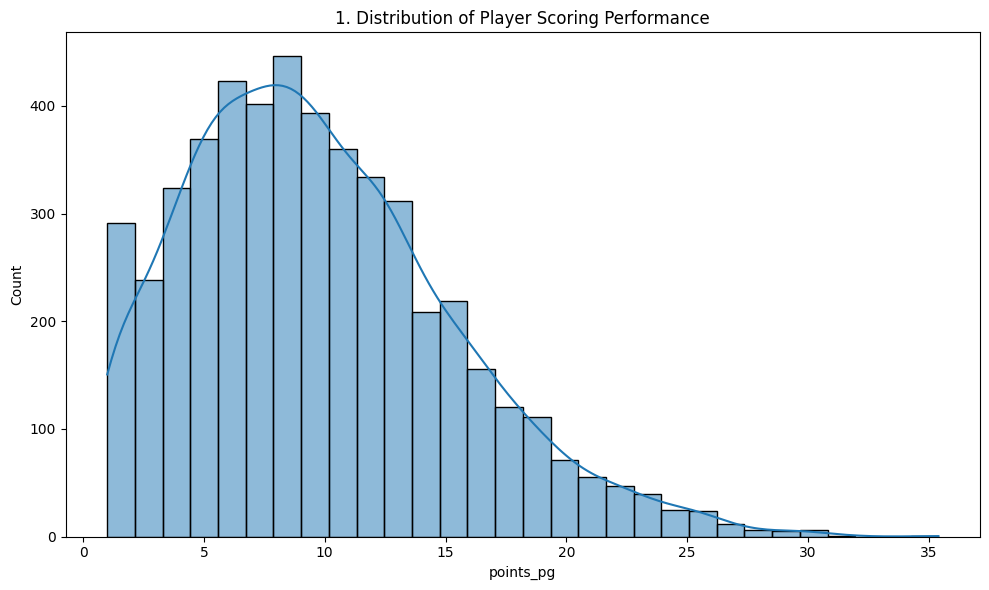

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='points_pg', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Player Scoring Performance')
show_fig()
plot_no += 1

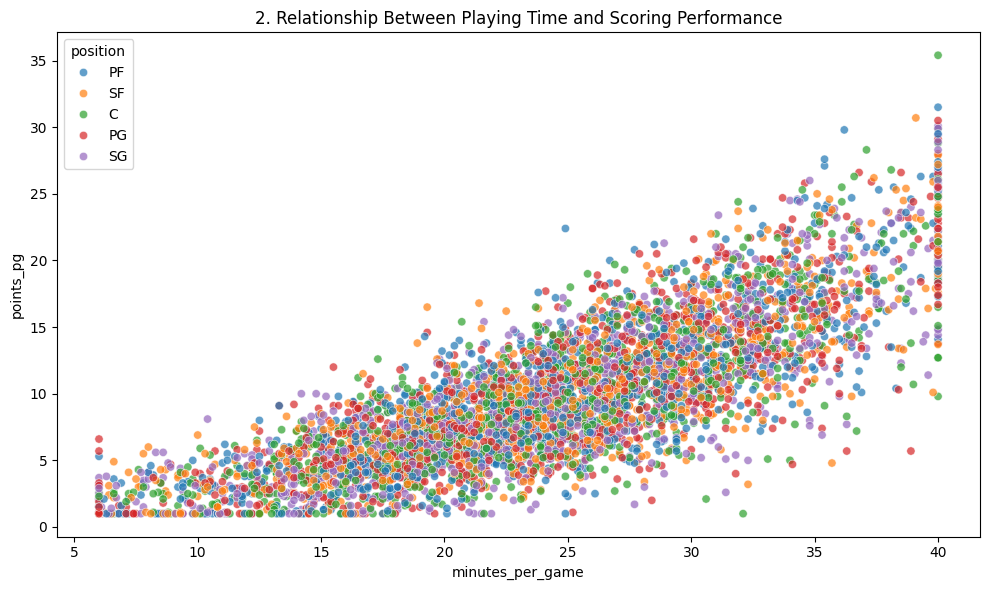

In [14]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='minutes_per_game', y='points_pg', hue='position', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Playing Time and Scoring Performance')
show_fig()
plot_no += 1

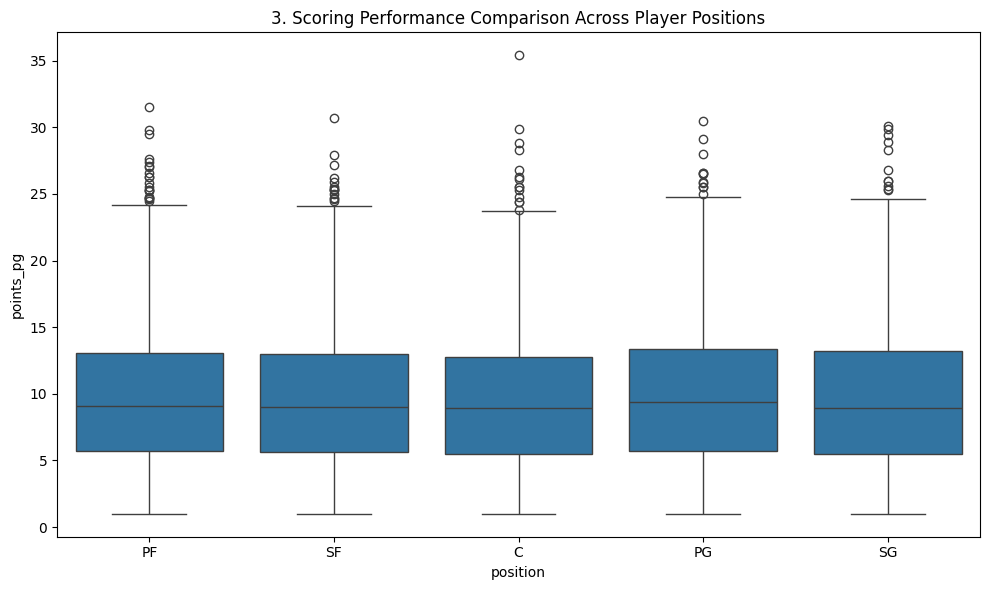

In [15]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='position', y='points_pg')
plt.title(f'{plot_no}. Scoring Performance Comparison Across Player Positions')
show_fig()
plot_no += 1

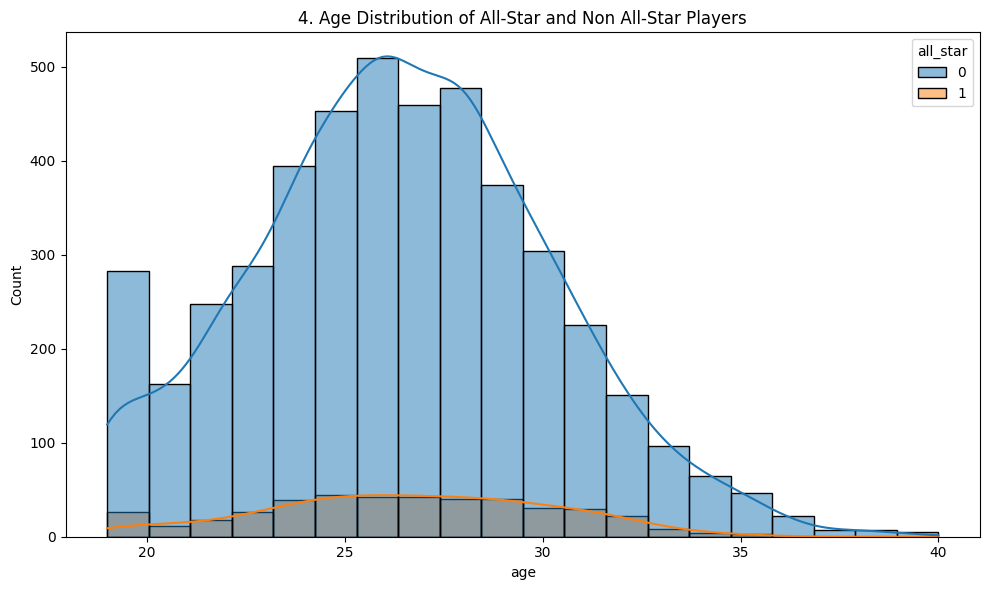

In [16]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='age', hue='all_star', kde=True, bins=20, multiple='layer')
plt.title(f'{plot_no}. Age Distribution of All-Star and Non All-Star Players')
show_fig()
plot_no += 1

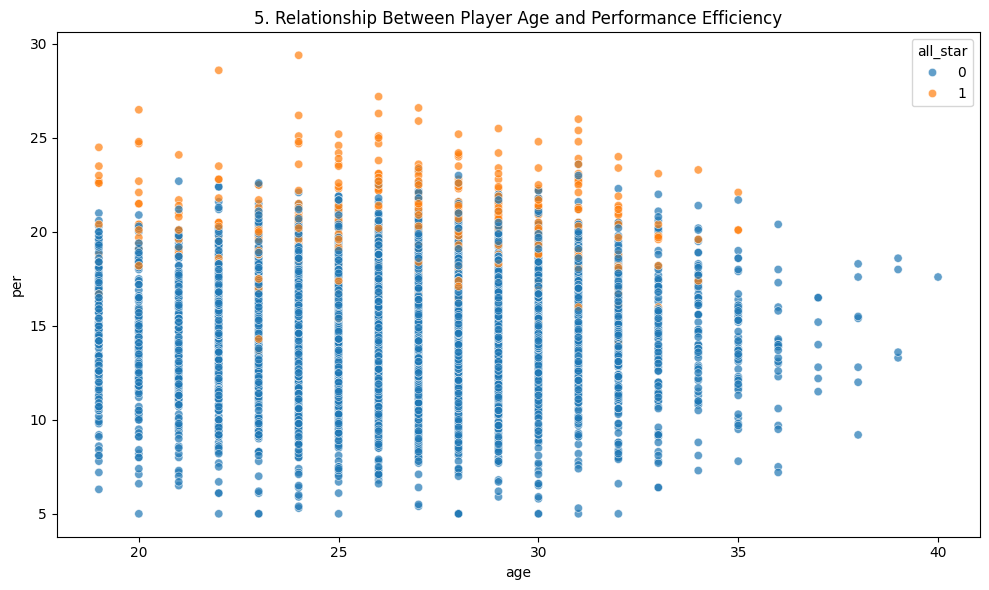

In [17]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='age', y='per', hue='all_star', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Player Age and Performance Efficiency')
show_fig()
plot_no += 1

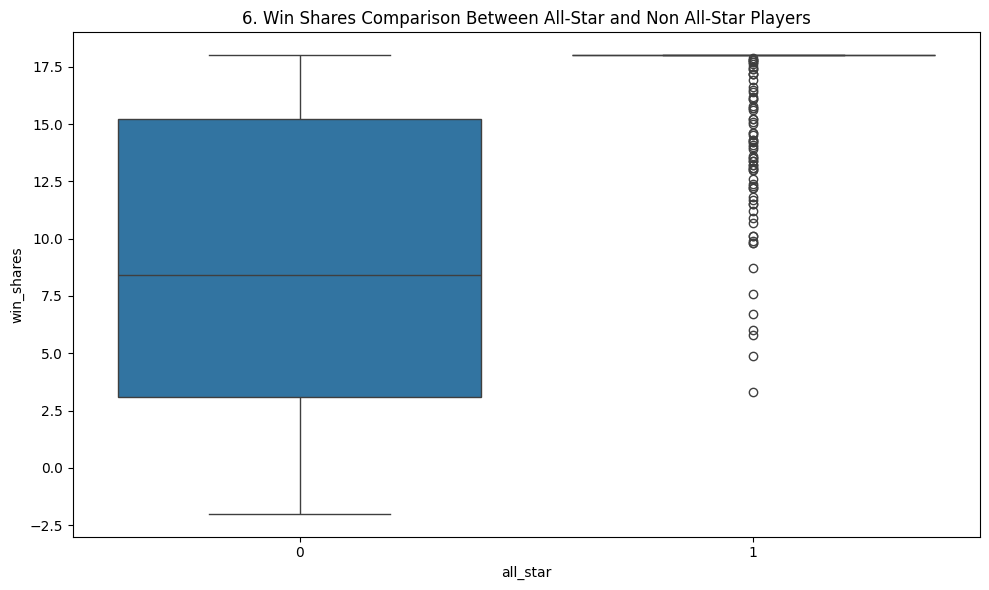

In [18]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='all_star', y='win_shares')
plt.title(f'{plot_no}. Win Shares Comparison Between All-Star and Non All-Star Players')
show_fig()
plot_no += 1

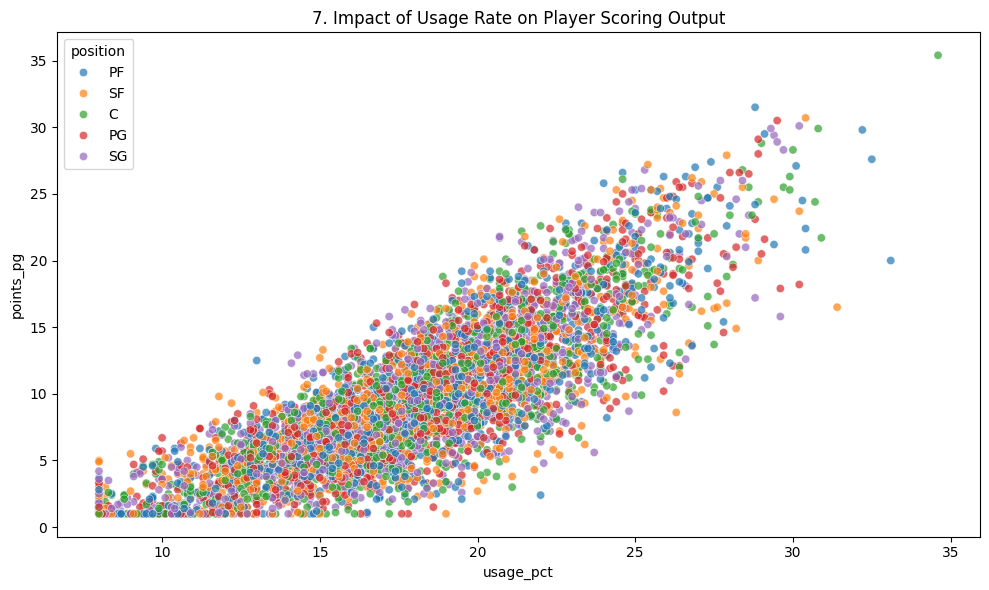

In [19]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='usage_pct', y='points_pg', hue='position', alpha=0.7)
plt.title(f'{plot_no}. Impact of Usage Rate on Player Scoring Output')
show_fig()
plot_no += 1

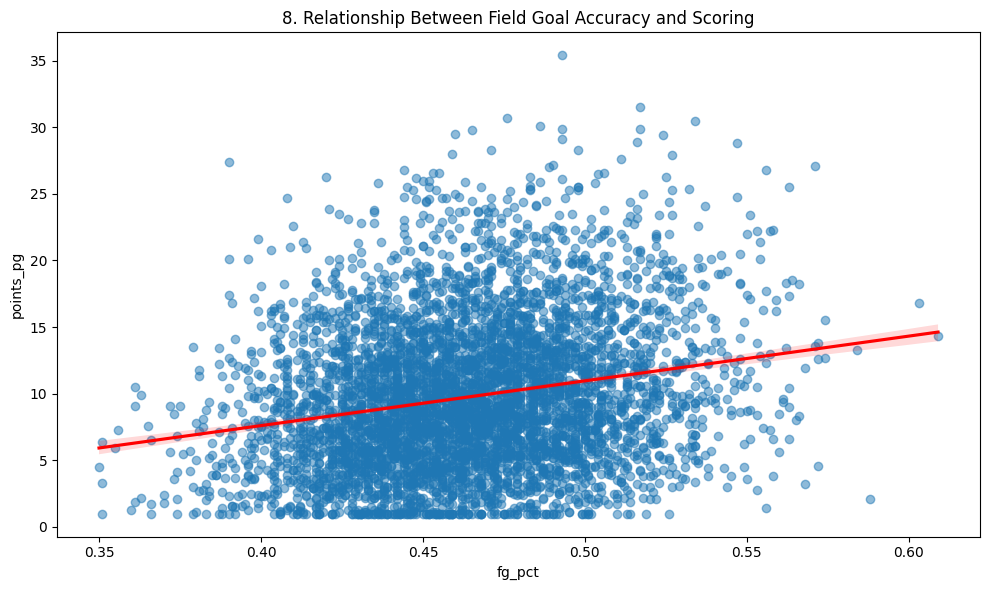

In [20]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='fg_pct', y='points_pg', scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Relationship Between Field Goal Accuracy and Scoring')
show_fig()
plot_no += 1

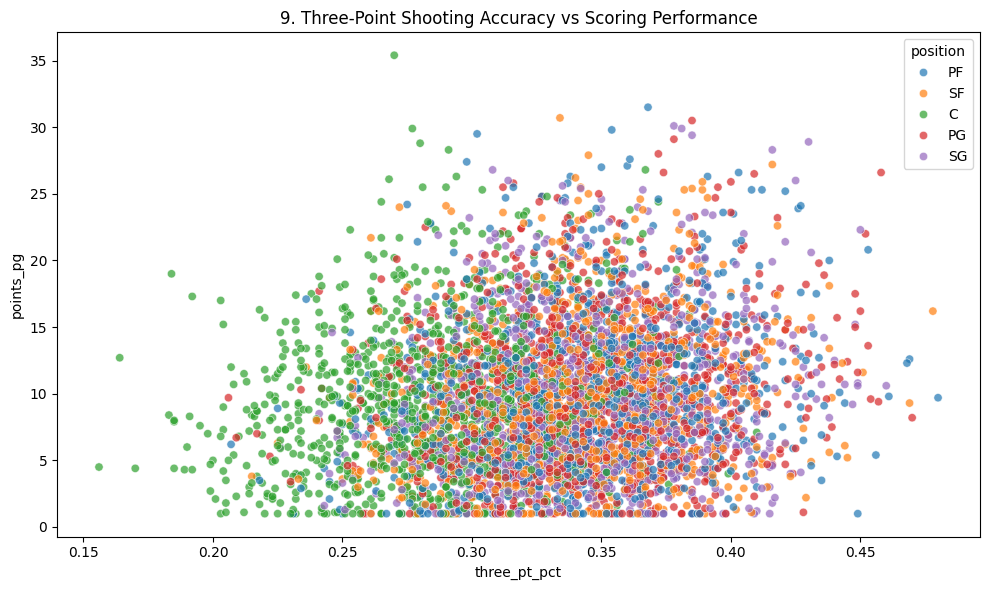

In [21]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='three_pt_pct', y='points_pg', hue='position', alpha=0.7)
plt.title(f'{plot_no}. Three-Point Shooting Accuracy vs Scoring Performance')
show_fig()
plot_no += 1

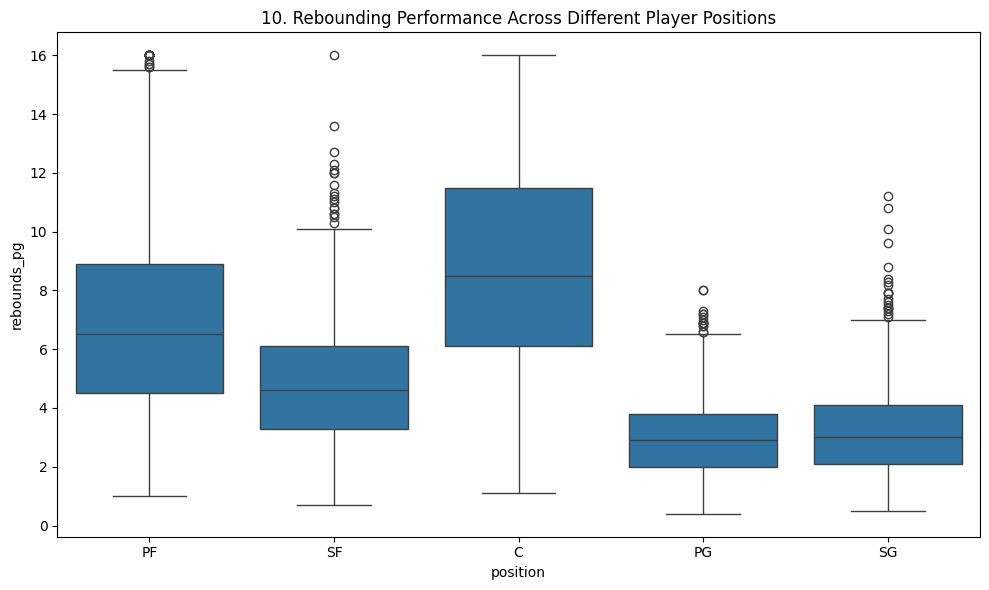

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='position', y='rebounds_pg')
plt.title(f'{plot_no}. Rebounding Performance Across Different Player Positions')
show_fig()
plot_no += 1

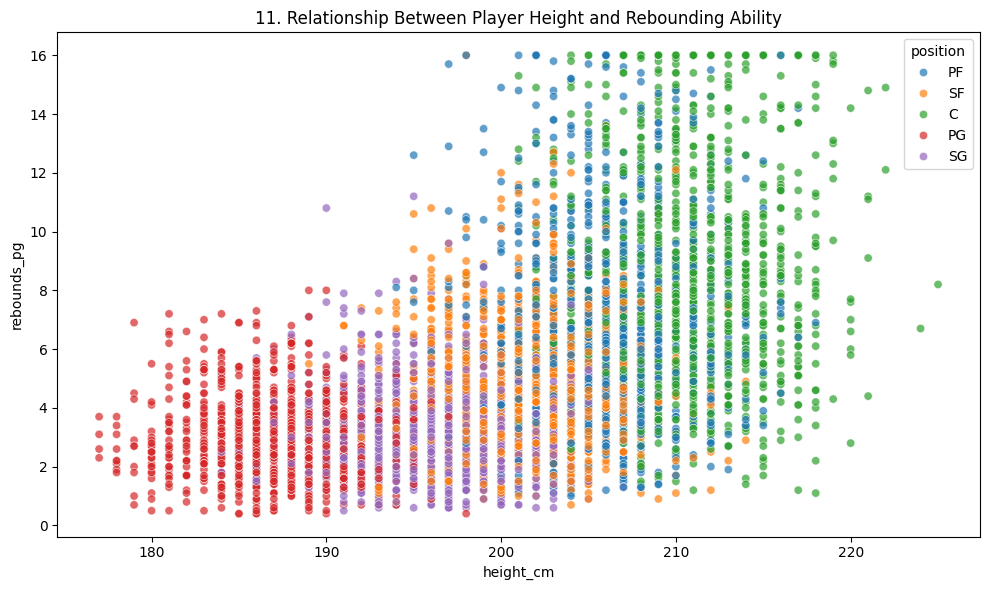

In [23]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='height_cm', y='rebounds_pg', hue='position', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Player Height and Rebounding Ability')
show_fig()
plot_no += 1

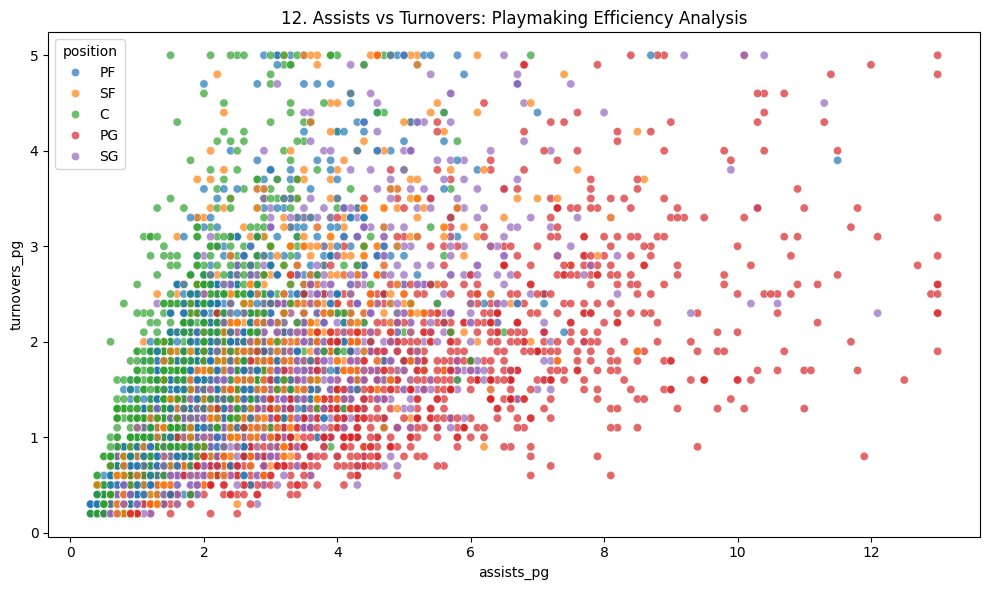

In [24]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='assists_pg', y='turnovers_pg', hue='position', alpha=0.7)
plt.title(f'{plot_no}. Assists vs Turnovers: Playmaking Efficiency Analysis')
show_fig()
plot_no += 1

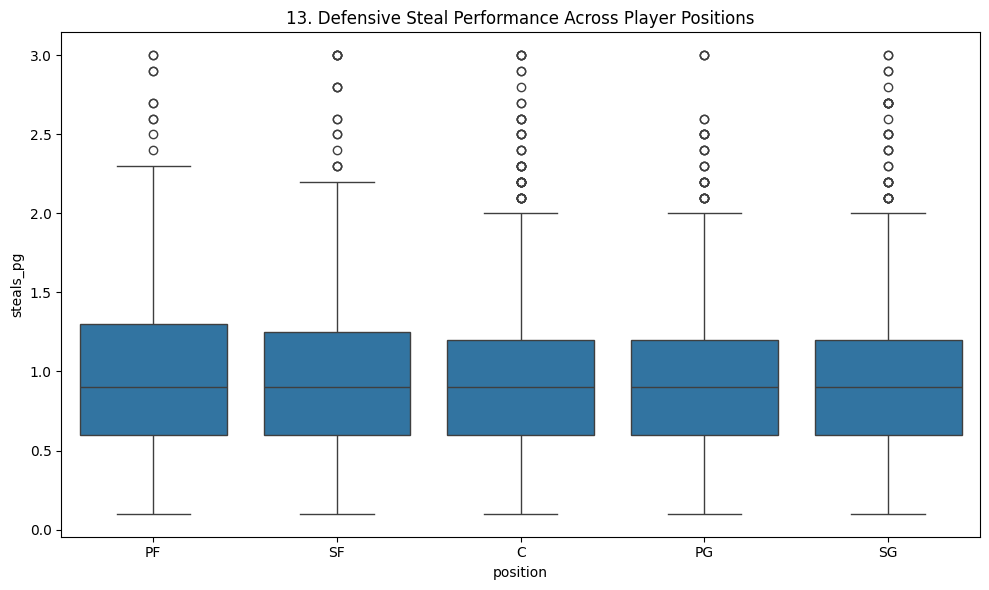

In [25]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='position', y='steals_pg')
plt.title(f'{plot_no}. Defensive Steal Performance Across Player Positions')
show_fig()
plot_no += 1

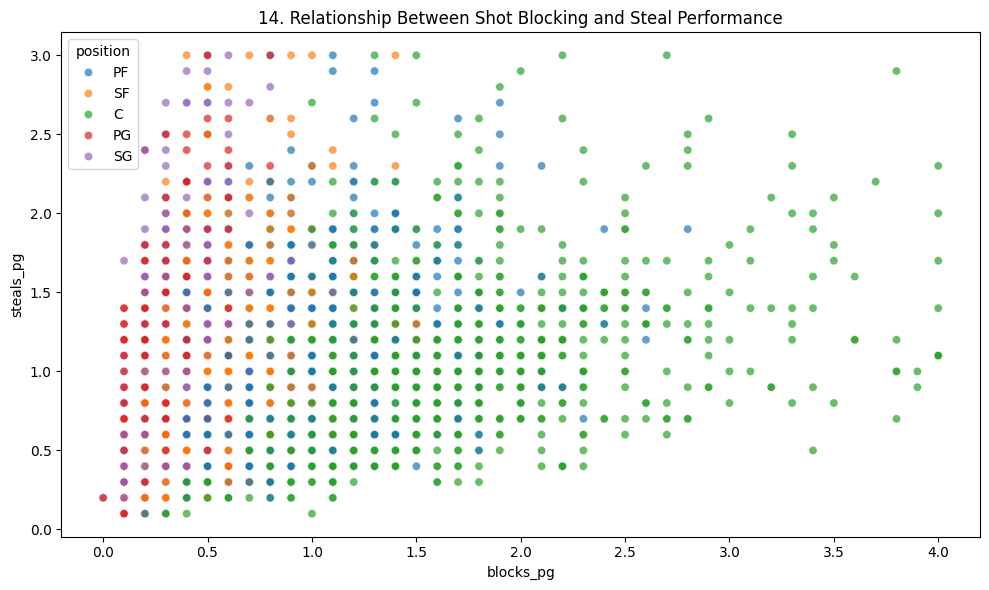

In [26]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='blocks_pg', y='steals_pg', hue='position', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Shot Blocking and Steal Performance')
show_fig()
plot_no += 1

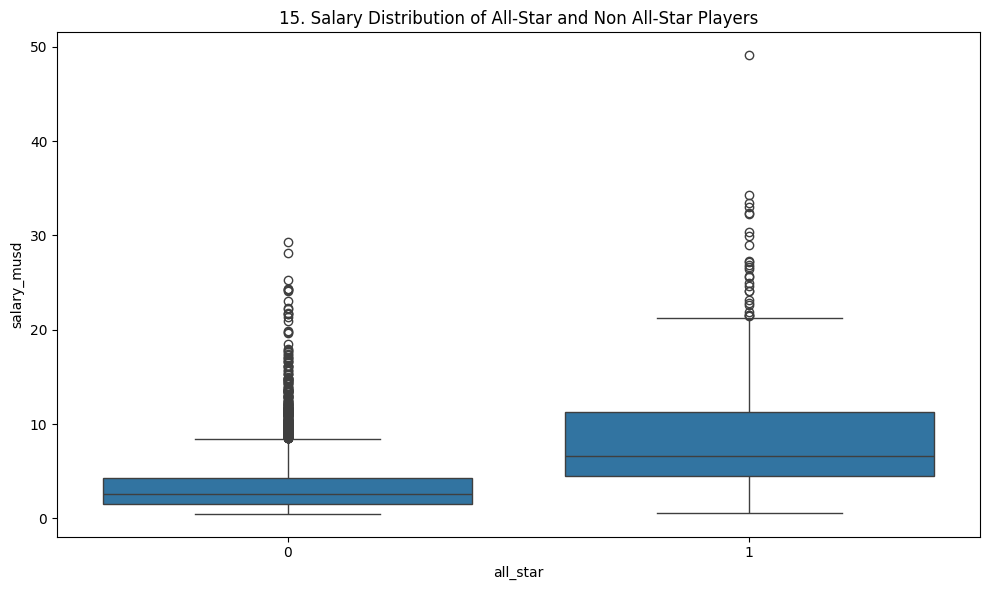

In [27]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='all_star', y='salary_musd')
plt.title(f'{plot_no}. Salary Distribution of All-Star and Non All-Star Players')
show_fig()
plot_no += 1

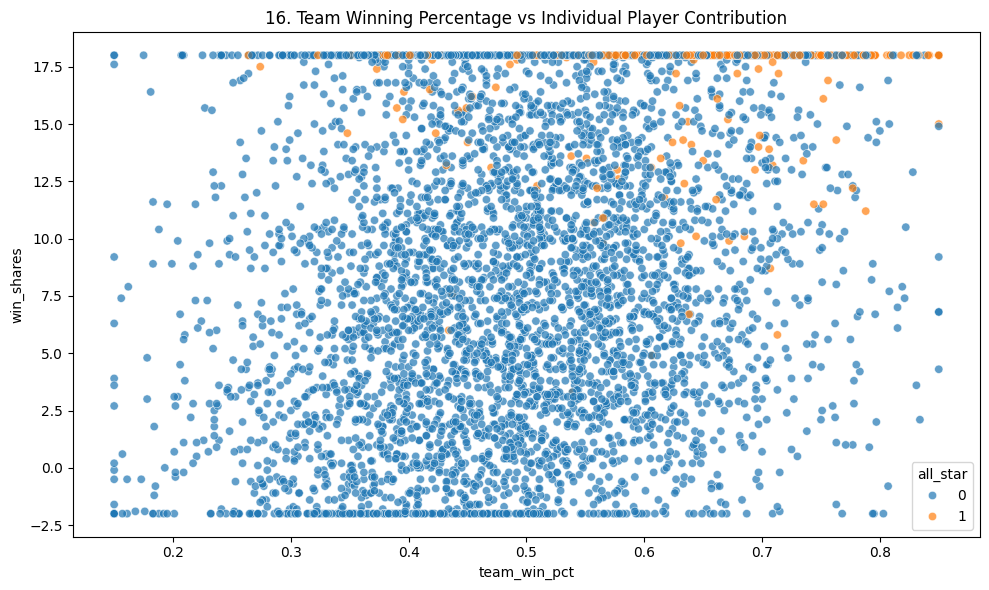

In [28]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='team_win_pct', y='win_shares', hue='all_star', alpha=0.7)
plt.title(f'{plot_no}. Team Winning Percentage vs Individual Player Contribution')
show_fig()
plot_no += 1

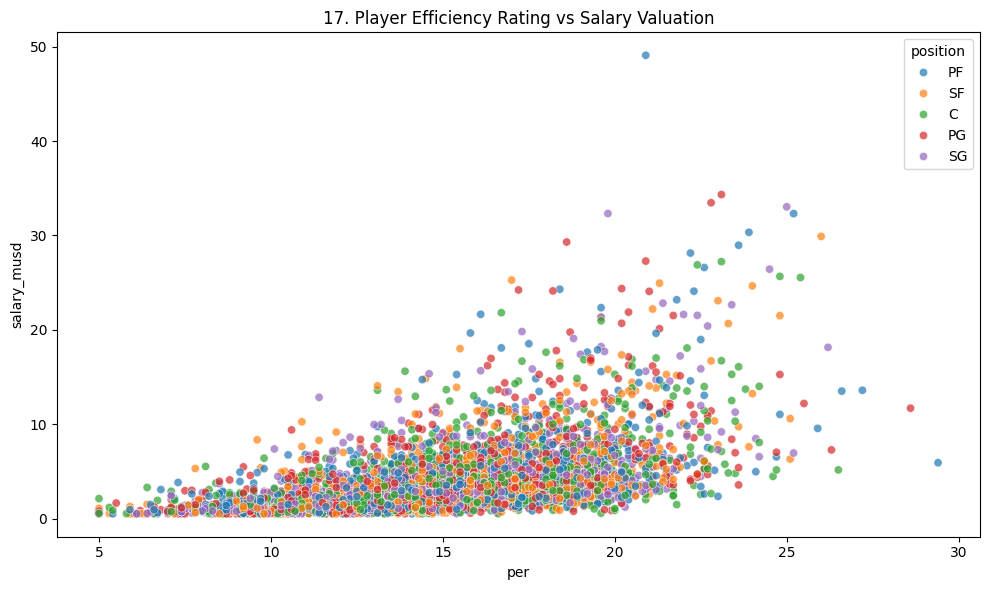

In [29]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='per', y='salary_musd', hue='position', alpha=0.7)
plt.title(f'{plot_no}. Player Efficiency Rating vs Salary Valuation')
show_fig()
plot_no += 1

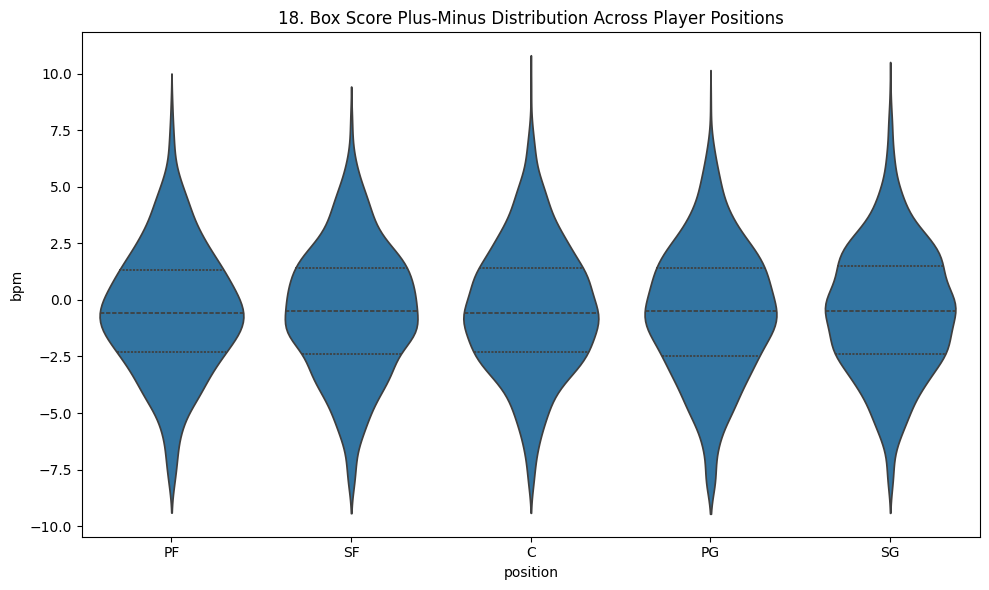

In [30]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='position', y='bpm', inner='quartile')
plt.title(f'{plot_no}. Box Score Plus-Minus Distribution Across Player Positions')
show_fig()
plot_no += 1

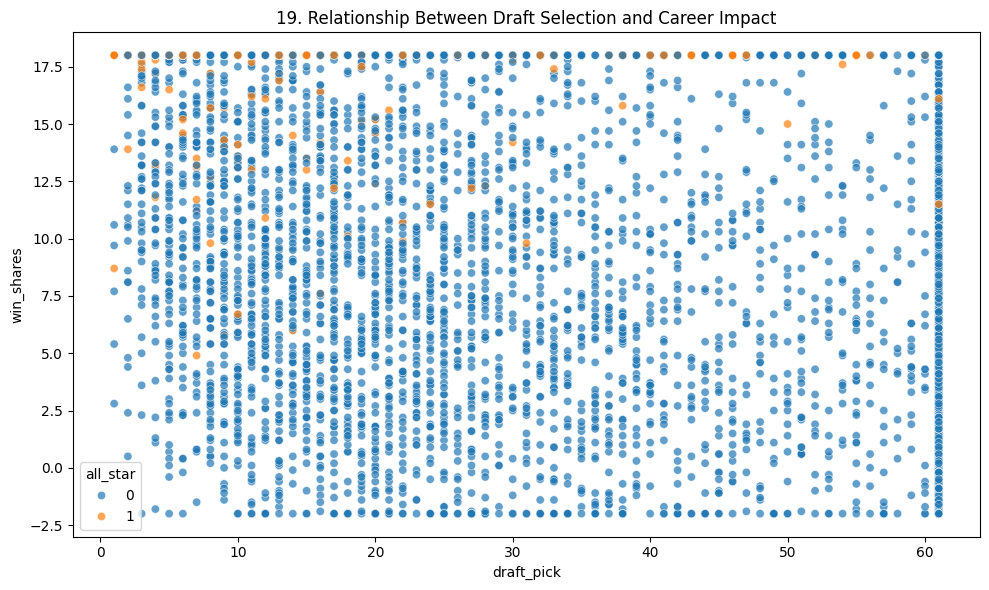

In [31]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='draft_pick', y='win_shares', hue='all_star', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Draft Selection and Career Impact')
show_fig()
plot_no += 1

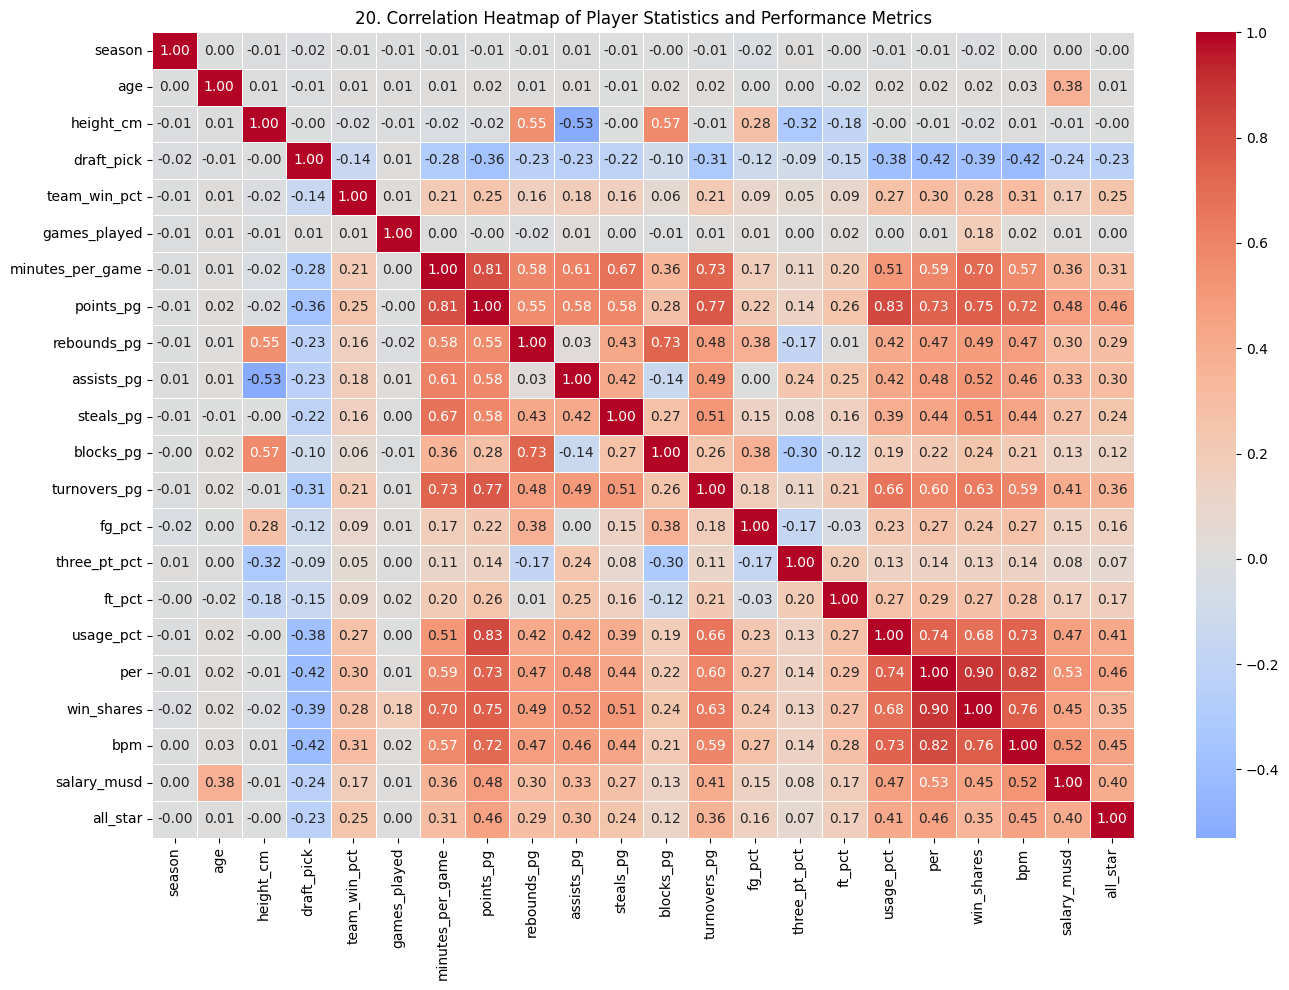

In [32]:
corr = df.select_dtypes(include='number').drop(columns=['player_season_id'], errors='ignore').corr()

fig = plt.figure(figsize=(14,10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, center=0)
plt.title(f'{plot_no}. Correlation Heatmap of Player Statistics and Performance Metrics')
show_fig()
plot_no += 1

# Model Training

## Select features and target

In [33]:
X = df.drop(columns=['all_star', 'player_season_id', 'player_name', 'season'])
y = df['all_star']

## Identify numerical and categorical columns

In [34]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(include='object').columns

## Create preprocessing pipeline

In [35]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_cols)
])

## Split dataset

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Create and train model

In [37]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=20,
        l2_regularization=1.0,
        random_state=42
    ))
])

model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Generate predictions

In [38]:
y_pred = model.predict(X_test)

## Evaluate model

In [39]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.938

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.97      0.97       915
           1       0.65      0.58      0.61        85

    accuracy                           0.94      1000
   macro avg       0.81      0.77      0.79      1000
weighted avg       0.93      0.94      0.94      1000



## Plot confusion matrix

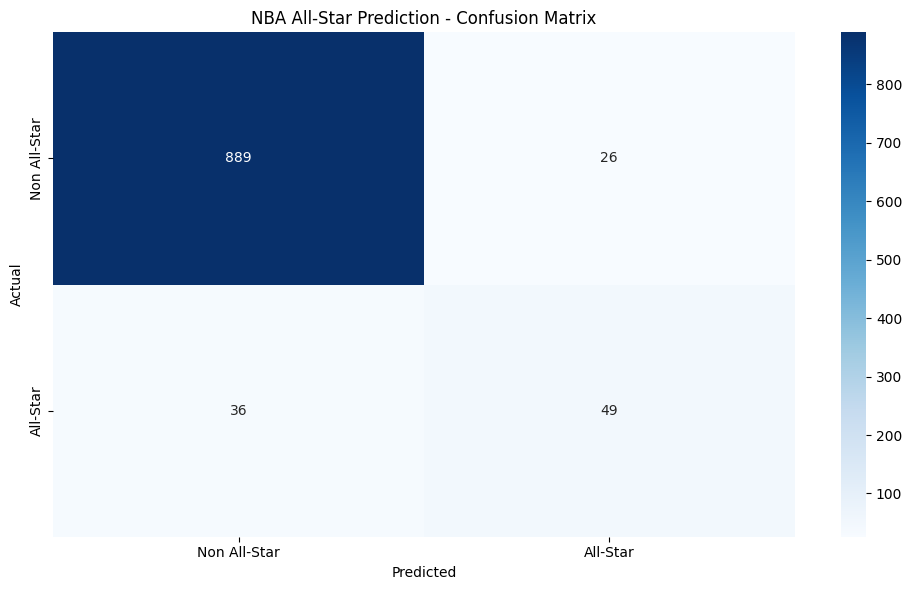

In [40]:
fig = plt.figure(figsize=(10,6))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non All-Star', 'All-Star'],
    yticklabels=['Non All-Star', 'All-Star']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('NBA All-Star Prediction - Confusion Matrix')
show_fig()